# ¿A qué precio vender? Regresión lineal (OLS) con `price_per_sqm` como target

**Decisiones de este notebook**
- Target: `price_per_sqm` (RUB por m²). El resultado final se **convierte a RUB** (`precio = ppsqm × total_area`) para poder compararlo con los modelos de `price_rub`.
- `price_rub` **no** puede ser predictora (el target se calcula con ella: fuga de información). `living_area` y `kitchen_area` quedan fuera por depender de `total_area`.
- Outliers: se quitan los anuncios cuyo `price_per_sqm` supera Q3 + 1,5·IQR **dentro de su okrug** (un departamento grande no es un outlier; uno caro *para su zona* sí).
- Validación: split **train/test 80/20** con semilla fija. Todas las métricas de error se reportan en train y en test.
- La decisión de usar **log** o no sobre el target se toma con evidencia (sección 1 y sección 5), no por costumbre.

**Orden:** 0. Setup → 1. Diagnóstico del target → 2. Outliers → 3. Funciones → 4. Corrida configurable → 5. Comparación lineal / semi-log / log mixto → 6. Diagnóstico final.

Corré las celdas de arriba hacia abajo.

## 0. Setup

In [5]:
%pip install -q mlflow statsmodels scikit-learn scipy matplotlib pandas seaborn

Note: you may need to restart the kernel to use updated packages.


In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.stattools import durbin_watson, jarque_bera, omni_normtest
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from IPython.display import display
import mlflow

sns.set_theme(style="whitegrid")

BASE_DIR = "/home/facucasa/Regresion_parcial"
EXPERIMENT_NAME = "Parcial_ppsqm"

os.makedirs(f"{BASE_DIR}/mlartifacts", exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{BASE_DIR}/mlflow.db")
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=f"file://{BASE_DIR}/mlartifacts")
mlflow.set_experiment(EXPERIMENT_NAME)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Artifacts en:", mlflow.get_experiment_by_name(EXPERIMENT_NAME).artifact_location)

Tracking URI: sqlite:////home/facucasa/Regresion_parcial/mlflow.db
Artifacts en: file:///home/facucasa/Regresion_parcial/mlartifacts


In [2]:
RUTA = "/home/facucasa/Regresion_parcial/dataset/"   # carpeta donde está secondary_market.csv (ajustala)

df = pd.read_csv(RUTA + "secondary_market.csv")
# --- Unión con district_prices_monthly (panel distrito × mes) ---
dpm = pd.read_csv(RUTA + "district_prices_monthly.csv")

def panel_mes_anterior(data, panel):
    """Variables del panel del MES ANTERIOR al anuncio, en su mismo distrito.
    Nunca usa el mes del propio anuncio. El primer mes de la serie (2020-01) queda en NaN."""
    p = panel.sort_values(["district", "year_month"]).copy()
    p["log_precio_distrito_mes_ant"] = np.log(p.groupby("district")["secondary_price_per_sqm"].shift(1))
    p["var_mensual_mes_ant"] = p.groupby("district")["secondary_mom_change_pct"].shift(1)
    ym = pd.to_datetime(data["date_posted"]).dt.strftime("%Y-%m")
    m = data[["district"]].assign(year_month=ym.values).merge(
        p[["district", "year_month", "log_precio_distrito_mes_ant", "var_mensual_mes_ant"]],
        on=["district", "year_month"], how="left")
    m.index = data.index
    return m[["log_precio_distrito_mes_ant", "var_mensual_mes_ant"]]

df = pd.concat([df, panel_mes_anterior(df, dpm)], axis=1)
n0 = len(df)
df = df.dropna(subset=["log_precio_distrito_mes_ant"]).reset_index(drop=True)   # descarta 2020-01 (sin mes previo)
df["var_mensual_mes_ant"] = df["var_mensual_mes_ant"].fillna(0)                  # solo 2020-02 queda vacío
print(f"Unión con el panel: {n0:,} → {len(df):,} anuncios (se descartan {n0 - len(df):,} sin mes previo)")

TARGET = "price_per_sqm"     # variable objetivo
PRICE = "price_rub"          # solo para convertir y evaluar en RUB (NUNCA como predictora)
AREA = "total_area"
SEED = 42

def show(tbl, dec=3):
    display(tbl.round(dec))

print(f"secondary_market: {len(df):,} filas × {df.shape[1]} columnas | duplicados: {df.duplicated().sum()}")
print("Nulos por columna (solo las que tienen):")
nulos = df.isna().sum()
print(nulos[nulos > 0].to_dict() or "ninguno")

# Chequeo de coherencia: price_per_sqm debería ser price_rub / total_area
ratio = (df[PRICE] / df[AREA]) / df[TARGET]
print(f"\n(price_rub / total_area) / price_per_sqm: media = {ratio.mean():.5f} | min = {ratio.min():.4f} | max = {ratio.max():.4f}")

Unión con el panel: 50,000 → 49,322 anuncios (se descartan 678 sin mes previo)
secondary_market: 49,322 filas × 28 columnas | duplicados: 0
Nulos por columna (solo las que tienen):
ninguno

(price_rub / total_area) / price_per_sqm: media = 1.00000 | min = 0.9978 | max = 1.0021


## 1. Diagnóstico del target: ¿conviene aplicarle log?

Tres evidencias que se miran **antes** de modelar:
1. **Asimetría y curtosis** de `price_per_sqm` vs `log(price_per_sqm)`.
2. **Varianza según el nivel**: si el desvío crece con la media entre okrugs, el log estabiliza la varianza (heterocedasticidad multiplicativa).
3. **Relación con la superficie** en log-log: la pendiente indica cómo cambia el precio por m² con el tamaño.

Forma de la distribución (0 = simétrica / normal):


,asimetría,curtosis
price_rub,1.994,6.535
price_per_sqm,1.685,4.298
log(price_per_sqm),-0.197,0.212


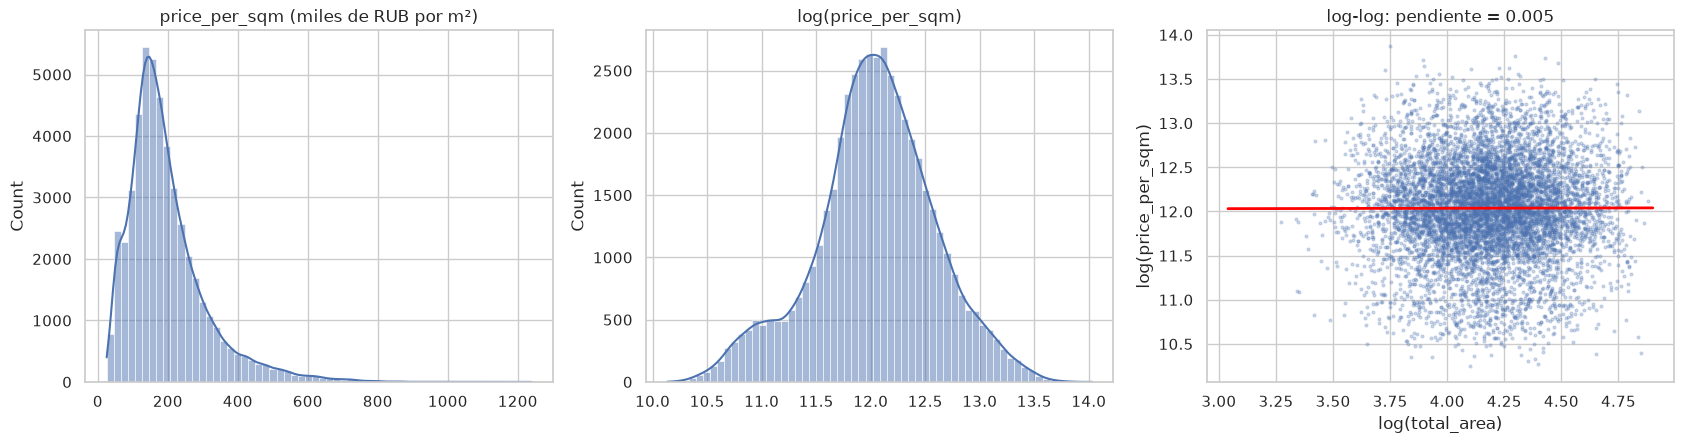

Pendiente log-log = 0.005. Si es ≈ 0, el precio total crece proporcionalmente a la superficie; si es negativa, los departamentos chicos tienen prima por m².

Precio por m² por okrug (escala original y en log):


,media,desvio,coef_var,desvio_en_log
okrug,,,,
CAO,450711.593,130654.616,0.290,0.289
ZAO,240408.694,89933.567,0.374,0.371
YuZAO,237566.709,79139.226,0.333,0.331
SZAO,223725.259,71498.124,0.320,0.304
SAO,195224.866,71750.233,0.368,0.359
VAO,174629.122,55208.729,0.316,0.302
SVAO,168208.471,50450.511,0.300,0.286
YuAO,168071.496,56433.195,0.336,0.317
NAO,101411.154,29243.529,0.288,0.274


Correlación media-desvío entre okrugs (escala original): 0.98
Desvío en log: de 0.228 a 0.371 (si es parejo y el desvío original crece con la media, el log homogeneiza la varianza)


In [3]:
sk = pd.DataFrame({
    "price_rub":            [df[PRICE].skew(), df[PRICE].kurt()],
    "price_per_sqm":        [df[TARGET].skew(), df[TARGET].kurt()],
    "log(price_per_sqm)":   [np.log(df[TARGET]).skew(), np.log(df[TARGET]).kurt()],
}, index=["asimetría", "curtosis"]).T
print("Forma de la distribución (0 = simétrica / normal):")
show(sk)

samp = df.sample(8000, random_state=SEED)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
sns.histplot(df[TARGET] / 1e3, bins=60, kde=True, ax=axes[0])
axes[0].set(title="price_per_sqm (miles de RUB por m²)", xlabel="")
sns.histplot(np.log(df[TARGET]), bins=60, kde=True, ax=axes[1])
axes[1].set(title="log(price_per_sqm)", xlabel="")
b, a = np.polyfit(np.log(df[AREA]), np.log(df[TARGET]), 1)
xs = np.linspace(np.log(df[AREA]).min(), np.log(df[AREA]).max(), 100)
axes[2].scatter(np.log(samp[AREA]), np.log(samp[TARGET]), s=4, alpha=0.25)
axes[2].plot(xs, a + b * xs, color="red", lw=2)
axes[2].set(xlabel="log(total_area)", ylabel="log(price_per_sqm)",
            title=f"log-log: pendiente = {b:.3f}")
plt.tight_layout()
plt.show()
print(f"Pendiente log-log = {b:.3f}. Si es ≈ 0, el precio total crece proporcionalmente a la superficie; "
      f"si es negativa, los departamentos chicos tienen prima por m².")

# Heterocedasticidad por nivel: ¿el desvío crece con la media?
g = df.groupby("okrug")[TARGET].agg(media="mean", desvio="std")
g["coef_var"] = g["desvio"] / g["media"]
g["desvio_en_log"] = np.log(df[TARGET]).groupby(df["okrug"]).std()
print("\nPrecio por m² por okrug (escala original y en log):")
show(g.sort_values("media", ascending=False), dec=3)
print(f"Correlación media-desvío entre okrugs (escala original): {g['media'].corr(g['desvio']):.2f}")
print(f"Desvío en log: de {g['desvio_en_log'].min():.3f} a {g['desvio_en_log'].max():.3f} "
      f"(si es parejo y el desvío original crece con la media, el log homogeneiza la varianza)")

## 2. Outliers sobre `price_per_sqm`

Criterio: `price_per_sqm` > Q3 + 1,5·IQR **dentro de cada okrug** (una sola pasada). Se filtran filas, no se crean columnas. `df_completo` conserva todos los anuncios.

Cambia respecto del notebook de `price_rub`: ahí se recortaban sobre todo departamentos grandes; acá se recortan anuncios caros **por m²** para su zona. Por eso los conjuntos filtrados no son idénticos y, al comparar contra el otro notebook, conviene hacerlo sobre las filas en común.

In [4]:
def mascara_iqr_grupo(data, col, grupo, k=1.5, solo_alto=True):
    """True = outlier según k·IQR de `col` dentro de cada categoría de `grupo`."""
    g = data[col].groupby(data[grupo])
    q1 = g.transform(lambda x: x.quantile(0.25))
    q3 = g.transform(lambda x: x.quantile(0.75))
    iqr = q3 - q1
    alto = data[col] > q3 + k * iqr
    return alto if solo_alto else (alto | (data[col] < q1 - k * iqr))

if "df_completo" not in globals():
    df_completo = df.copy()

# Primero ver qué pasaría con alto Y bajo, para decidir si hace falta recortar los dos lados
m_ambos = mascara_iqr_grupo(df_completo, TARGET, "okrug", solo_alto=False)
m_alto = mascara_iqr_grupo(df_completo, TARGET, "okrug", solo_alto=True)
print(f"Outliers por IQR dentro del okrug: lado alto = {int(m_alto.sum()):,} | "
      f"lado bajo = {int(m_ambos.sum() - m_alto.sum()):,}")

# Criterio elegido: ambos lados (un precio/m² anormalmente bajo también es un dato dudoso)
mask = m_ambos
df = df_completo.loc[~mask].reset_index(drop=True)
print(f"Completo: {len(df_completo):,} → sin outliers: {len(df):,} (se quitaron {int(mask.sum()):,}, {100*mask.mean():.2f} %)")

perd = pd.concat([df_completo[mask].groupby("okrug").size(), df_completo.groupby("okrug").size()],
                 axis=1, keys=["quitadas", "total"]).fillna(0)
perd["% del okrug"] = 100 * perd["quitadas"] / perd["total"]
print("\nAnuncios quitados por okrug (que ninguna zona quede desproporcionadamente recortada):")
show(perd.sort_values("% del okrug").T, dec=1)

comp = pd.DataFrame({
    "completo": {"media": df_completo[TARGET].mean(), "mediana": df_completo[TARGET].median(),
                 "máximo": df_completo[TARGET].max(), "asimetría": df_completo[TARGET].skew()},
    "sin outliers": {"media": df[TARGET].mean(), "mediana": df[TARGET].median(),
                     "máximo": df[TARGET].max(), "asimetría": df[TARGET].skew()}})
print("\nEfecto del filtro sobre price_per_sqm:")
show(comp, dec=2)

Outliers por IQR dentro del okrug: lado alto = 1,145 | lado bajo = 0
Completo: 49,322 → sin outliers: 48,177 (se quitaron 1,145, 2.32 %)

Anuncios quitados por okrug (que ninguna zona quede desproporcionadamente recortada):


okrug,ZelAO,YuZAO,CAO,SAO,ZAO,TAO,VAO,SZAO,SVAO,NAO,YuAO
quitadas,4.0,69.0,57.0,92.0,83.0,79.0,158.0,97.0,191.0,126.0,189.0
total,357.0,4701.0,3847.0,5787.0,4555.0,3893.0,5999.0,3373.0,6552.0,4115.0,6143.0
% del okrug,1.1,1.5,1.5,1.6,1.8,2.0,2.6,2.9,2.9,3.1,3.1



Efecto del filtro sobre price_per_sqm:


,completo,sin outliers
media,196398.98,192317.73
mediana,171200.00,169000.00
máximo,1239100.00,785900.00
asimetría,1.68,1.63


## 3. Funciones de modelado

- **Split** train/test (80/20, semilla fija) hecho **dentro** de la corrida sobre el índice: las dummies se construyen con todo el dataset, así nunca faltan columnas en test.
- **Log en las predictoras**: solo las que se listan en `LOG_FEATS` (se usa `log(x)` si x > 0; `log1p(x)` si hay ceros; sin cambios si hay negativos o es binaria). No se agregan columnas a `df`.
- **Métricas de error** en dos escalas: RUB/m² (la del target) y **RUB totales** (`ppsqm_predicho × total_area`), que es la comparable entre notebooks. Con log se reportan también las versiones con corrección de Duan.
- `PONDERAR_AREA` (solo sin log): mínimos cuadrados ponderados con peso `total_area²`, que equivale a minimizar el error en RUB totales en lugar del error en RUB/m².

In [3]:
def transformar_numericas(data, num_feats, log_feats):
    """(X_num, lista_de_transformadas). No agrega columnas a `data`."""
    Xn, hechas = pd.DataFrame(index=data.index), []
    for c in num_feats:
        s = data[c].astype(float)
        if c in log_feats and s.nunique() > 2:
            if s.min() > 0:
                Xn[f"log_{c}"] = np.log(s); hechas.append(c)
            elif s.min() == 0:
                Xn[f"log1p_{c}"] = np.log1p(s); hechas.append(f"{c} (log1p)")
            else:
                Xn[c] = s
        else:
            Xn[c] = s
    return Xn, hechas

def build_X(data, num_feats, cat_feats, log_feats=()):
    Xn, hechas = transformar_numericas(data, num_feats, log_feats)
    partes = [Xn]
    if cat_feats:
        partes.append(pd.get_dummies(data[list(cat_feats)], drop_first=True, dtype=float))
    return sm.add_constant(pd.concat(partes, axis=1), has_constant="add"), hechas

def residual_plots(res, X, num_cols):
    infl = res.get_influence()
    fitted, resid, stud = res.fittedvalues, res.resid, infl.resid_studentized_internal
    figs = {}

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(fitted, resid, s=4, alpha=0.2); ax.axhline(0, color="red", lw=1)
    ax.set(xlabel="Valores ajustados", ylabel="Residuos", title="Residuos vs ajustados")
    figs["resid_vs_fitted"] = fig

    fig, ax = plt.subplots(figsize=(6, 6))
    sm.qqplot(stud, line="45", ax=ax, markersize=2, alpha=0.3)
    ax.set_title("QQ-plot (residuos studentizados)")
    figs["qq_plot"] = fig

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(resid, bins=80, density=True, alpha=0.7)
    xs = np.linspace(resid.min(), resid.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), color="red", lw=1)
    ax.set(xlabel="Residuos", ylabel="Densidad", title="Distribución de residuos")
    figs["resid_hist"] = fig

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(fitted, np.sqrt(np.abs(stud)), s=4, alpha=0.2)
    ax.set(xlabel="Valores ajustados", ylabel="√|residuo studentizado|", title="Scale-Location")
    figs["scale_location"] = fig

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(infl.hat_matrix_diag, stud, s=4, alpha=0.2); ax.axhline(0, color="red", lw=1)
    ax.set(xlabel="Leverage", ylabel="Residuo studentizado", title="Leverage vs residuos")
    figs["leverage_vs_resid"] = fig

    n = len(num_cols)
    if n:
        cols = 3
        rows = int(np.ceil(n / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.5 * rows), squeeze=False)
        for ax, feat in zip(axes.ravel(), num_cols):
            ax.scatter(X[feat], resid, s=3, alpha=0.15); ax.axhline(0, color="red", lw=1)
            ax.set(xlabel=feat, ylabel="Residuos")
        for ax in axes.ravel()[n:]:
            ax.axis("off")
        fig.suptitle("Residuos vs predictoras numéricas")
        fig.tight_layout()
        figs["resid_vs_features"] = fig
    return figs

def _errores(data, idx, p_ppsqm):
    """Errores en RUB/m² y en RUB totales (ppsqm_predicho × total_area)."""
    y_m2, y_rub = data.loc[idx, TARGET], data.loc[idx, PRICE]
    p_rub = p_ppsqm * data.loc[idx, AREA]
    return {"rmse_m2": np.sqrt(mean_squared_error(y_m2, p_ppsqm)),
            "mae_m2": mean_absolute_error(y_m2, p_ppsqm),
            "rmse_rub": np.sqrt(mean_squared_error(y_rub, p_rub)),
            "mae_rub": mean_absolute_error(y_rub, p_rub),
            "mape_pct": 100 * float(np.mean(np.abs(y_rub - p_rub) / y_rub))}

def run_ppsqm(num_feats, cat_feats, run_name, notes, log_target, log_feats=(),
              ponderar_area=False, usar_completo=False):
    num_feats, cat_feats, log_feats = list(num_feats), list(cat_feats), list(log_feats)
    datos = df_completo if usar_completo else df
    faltan = [c for c in num_feats + cat_feats if c not in datos.columns]
    assert not faltan, f"Columnas inexistentes: {faltan}"
    assert PRICE not in num_feats + cat_feats, "price_rub como predictora = fuga de información"
    assert TARGET not in num_feats + cat_feats, "el target no puede ser predictora"
    assert not (ponderar_area and log_target), "PONDERAR_AREA solo aplica sin log en el target"

    X, hechas = build_X(datos, num_feats, cat_feats, log_feats)
    y = np.log(datos[TARGET]) if log_target else datos[TARGET].astype(float)
    tr, te = train_test_split(datos.index, test_size=0.2, random_state=SEED)
    Xtr, Xte = X.loc[tr], X.loc[te]

    with mlflow.start_run(run_name=run_name) as run:
        if ponderar_area:
            res = sm.WLS(y.loc[tr], Xtr, weights=datos.loc[tr, AREA] ** 2).fit()
        else:
            res = sm.OLS(y.loc[tr], Xtr).fit()

        spec = ("lineal" if not log_target else
                ("log-log" if hechas else "semi-log"))
        if ponderar_area:
            spec += " (WLS área²)"
        mlflow.log_params({
            "target": TARGET, "log_target": log_target,
            "num_features": ", ".join(num_feats), "cat_features": ", ".join(cat_feats),
            "log_features": ", ".join(hechas) if hechas else "ninguna",
            "n_features_total": X.shape[1] - 1, "ponderar_area": ponderar_area,
            "dataset": "completo" if usar_completo else "sin_outliers",
            "n_train": len(tr), "n_test": len(te),
        })
        mlflow.set_tags({"model_type": "WLS" if ponderar_area else "OLS", "spec": spec})
        if notes:
            mlflow.set_tag("notes", notes)

        # --- Estadísticos del modelo (sobre train, en la escala del target ajustado) ---
        omni, omni_p = omni_normtest(res.resid)
        jb, jb_p, skew, kurt = jarque_bera(res.resid)
        m = {"r2": res.rsquared, "r2_adj": res.rsquared_adj, "f_statistic": res.fvalue,
             "f_pvalue": res.f_pvalue, "log_likelihood": res.llf, "aic": res.aic, "bic": res.bic,
             "nobs": res.nobs, "df_model": res.df_model, "df_resid": res.df_resid,
             "omnibus": omni, "omnibus_pvalue": omni_p, "durbin_watson": durbin_watson(res.resid),
             "jarque_bera": jb, "jarque_bera_pvalue": jb_p, "skew": skew, "kurtosis": kurt,
             "cond_no": res.condition_number}

        # --- Errores en train y test, en RUB/m² y en RUB totales ---
        p_tr, p_te = res.predict(Xtr), res.predict(Xte)
        if log_target:
            p_tr, p_te = np.exp(p_tr), np.exp(p_te)
            duan = float(np.mean(np.exp(res.resid)))      # corrección de Duan (calculada en train)
            m["duan_factor"] = duan
            variantes = {"": 1.0, "_duan": duan}
        else:
            variantes = {"": 1.0}
        for suf, f in variantes.items():
            for nombre, idx, p in [("train", tr, p_tr), ("test", te, p_te)]:
                for k, v in _errores(datos, idx, p * f).items():
                    m[f"{nombre}_{k}{suf}"] = v
        mlflow.log_metrics({k: float(v) for k, v in m.items()})

        # --- Artefactos ---
        mlflow.log_text(str(res.summary()), "summary.txt")
        ct = pd.concat([res.params, res.bse, res.tvalues, res.pvalues, res.conf_int()], axis=1)
        ct.columns = ["coef", "std_err", "t", "p_value", "ci_low", "ci_high"]
        mlflow.log_text(ct.to_csv(), "coefficients.csv")
        num_cols = [c for c in Xtr.columns if c in transformar_numericas(datos.head(5), num_feats, log_feats)[0].columns
                    or c in num_feats]
        # Los resultados WLS no traen get_influence: se diagnostica un OLS equivalente sobre datos
        # transformados por √peso (residuos ponderados, los que realmente minimiza el WLS).
        if ponderar_area:
            w = np.sqrt(datos.loc[tr, AREA] ** 2)
            res_diag = sm.OLS(y.loc[tr] * w, Xtr.mul(w, axis=0)).fit()
            X_diag = Xtr.mul(w, axis=0)
        else:
            res_diag, X_diag = res, Xtr
        for fname, fig in residual_plots(res_diag, X_diag, num_cols).items():
            mlflow.log_figure(fig, f"plots/{fname}.png")
            plt.close(fig)

        print(f"[{spec}] {run_name} | run {run.info.run_id[:8]}")
        print(f"  Transformadas: {hechas if hechas else 'ninguna'}")
        print(f"  Test  → RMSE = {m['test_rmse_rub']:,.0f} RUB | MAE = {m['test_mae_rub']:,.0f} RUB | "
              f"MAPE = {m['test_mape_pct']:.1f} % | RMSE = {m['test_rmse_m2']:,.0f} RUB/m²")
        print(f"  Train → RMSE = {m['train_rmse_rub']:,.0f} RUB (diferencia train/test = señal de sobreajuste)")
    return res, m

## 4. Corrida configurable (editar solo la primera celda)

LOG_TARGET: aplica transformacion logaritmica al target.

In [4]:
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split

K_POR_OKRUG = 3    # 3 grupos de precio dentro de cada okrug

# Mismo split que usa run_ppsqm: los grupos se calculan SOLO con entrenamiento
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, random_state=SEED)

# Nivel de precio de cada distrito (promedio del log del precio por m², solo train)
nivel = df.loc[idx_tr].groupby("district")["price_per_sqm"].apply(lambda s: np.log(s).mean())
okrug_de = df.groupby("district")["okrug"].first().reindex(nivel.index)

# Dentro de cada okrug, agrupar sus distritos por nivel de precio (_0 = más barato)
mapa = {}
for ok, sub in nivel.groupby(okrug_de):
    k = min(K_POR_OKRUG, len(sub))
    if k == 1:
        etiquetas = np.zeros(len(sub), dtype=int)
    else:
        km = KMeans(k, n_init=10, random_state=SEED).fit(sub.values.reshape(-1, 1))
        rango = km.cluster_centers_.ravel().argsort().argsort()      # 0 = grupo más barato
        etiquetas = rango[km.labels_]
    for distrito, e in zip(sub.index, etiquetas):
        mapa[distrito] = f"{ok}_{e}"

# Columna nueva (un distrito sin datos en train quedaría en el grupo _0 de su okrug)
df["grupo_distrito"] = df["district"].map(mapa).fillna(df["okrug"] + "_0")

print(df.groupby("grupo_distrito")["district"].nunique().to_string())
print("Grupos:", df["grupo_distrito"].nunique())

grupo_distrito
CAO_0      3
CAO_1      2
CAO_2      5
NAO_0      4
NAO_1      6
NAO_2      1
SAO_0      1
SAO_1      7
SAO_2      7
SVAO_0     4
SVAO_1     8
SVAO_2     5
SZAO_0     5
SZAO_1     2
SZAO_2     2
TAO_0      7
TAO_1      2
TAO_2      1
VAO_0      7
VAO_1      6
VAO_2      3
YuAO_0     8
YuAO_1     5
YuAO_2     3
YuZAO_0    2
YuZAO_1    5
YuZAO_2    5
ZAO_0      3
ZAO_1      3
ZAO_2      6
ZelAO_0    1
Grupos: 31


In [5]:
RUN_NAME   = "ppsqm + grupos por okrug sin district prices monthly"
NOTAS      = "Target log; sacamos el district prices monthly para ver que tanto empeora"
LOG_TARGET = True
LOG_FEATS  = []

NUM_FEATS  = ["to_center_km", "metro_distance_min", "floor", "has_balcony"]
CAT_FEATS  = ["grupo_distrito", "renovation", "building_type", "metro_distance_type"]

PONDERAR_AREA = False
USAR_COMPLETO = False

res_run, met_run = run_ppsqm(NUM_FEATS, CAT_FEATS, RUN_NAME, NOTAS, LOG_TARGET)

[semi-log] ppsqm + grupos por okrug sin district prices monthly | run 613bd3b2
  Transformadas: ninguna
  Test  → RMSE = 2,723,971 RUB | MAE = 1,855,816 RUB | MAPE = 14.4 % | RMSE = 39,241 RUB/m²
  Train → RMSE = 2,720,895 RUB (diferencia train/test = señal de sobreajuste)


In [8]:
from sklearn.model_selection import RepeatedKFold

def cv_ols(num_feats, cat_feats, log_target, log_feats=(), usar_completo=False,
           k=5, repeticiones=3, seed=SEED):
    """K-fold repetido sobre las mismas filas y la misma matriz que usa run_ppsqm.
    Errores en RUB totales (ppsqm_predicho × AREA), igual que _errores."""
    datos = df_completo if usar_completo else df
    X, _ = build_X(datos, list(num_feats), list(cat_feats), list(log_feats))   # ya trae la constante
    y = np.log(datos[TARGET]) if log_target else datos[TARGET].astype(float)
    area, precio, ppsqm = datos[AREA].values, datos[PRICE].values, datos[TARGET].values

    filas = []
    rkf = RepeatedKFold(n_splits=k, n_repeats=repeticiones, random_state=seed)
    for i, (tr, te) in enumerate(rkf.split(X)):
        m = sm.OLS(y.iloc[tr], X.iloc[tr]).fit()
        pred_log = m.predict(X.iloc[te])
        if log_target:
            smear = np.mean(np.exp(m.resid))            # Duan calculado solo con el train del fold
            pred = np.exp(pred_log) * smear
        else:
            pred = pred_log
        err = precio[te] - pred * area[te]
        filas.append({"fold": i,
                      "rmse_rub": np.sqrt(np.mean(err ** 2)),
                      "mae_rub": np.mean(np.abs(err)),
                      "mape_pct": 100 * np.mean(np.abs(err) / precio[te]),
                      "rmse_m2": np.sqrt(np.mean((ppsqm[te] - pred) ** 2))})
    r = pd.DataFrame(filas)
    print(r.drop(columns="fold").agg(["mean", "std", "min", "max"]).round(1))
    return r

cv = cv_ols(NUM_FEATS, CAT_FEATS, LOG_TARGET, log_feats=LOG_FEATS, usar_completo=USAR_COMPLETO)

       rmse_rub    mae_rub  mape_pct  rmse_m2
mean  1761248.2  1156015.4       8.8  25345.7
std     28308.8    11404.3       0.1    290.1
min   1716489.8  1139787.6       8.7  24907.3
max   1825180.3  1181712.6       8.9  26048.3


## 5. Nuevo experimento con alquileres

In [9]:
EXPERIMENT_ALQ = "Parcial_Alquileres"
if mlflow.get_experiment_by_name(EXPERIMENT_ALQ) is None:
    mlflow.create_experiment(EXPERIMENT_ALQ, artifact_location=f"file://{BASE_DIR}/mlartifacts")
EXP_ALQ_ID = mlflow.get_experiment_by_name(EXPERIMENT_ALQ).experiment_id   # no se usa set_experiment: el de ventas sigue activo
print("Experimento de alquileres:", EXPERIMENT_ALQ, "| id:", EXP_ALQ_ID)

Experimento de alquileres: Parcial_Alquileres | id: 6


In [10]:
RENT_M2, RENT_TOTAL, AREA_ALQ = "rent_per_sqm", "monthly_rent_rub", "total_area"

df_rent = pd.read_csv(RUTA + "rentals.csv")
dpm_alq = pd.read_csv(RUTA + "district_prices_monthly.csv")
print(f"rentals: {len(df_rent):,} filas × {df_rent.shape[1]} columnas | nulos: {int(df_rent.isna().sum().sum())} | duplicados: {df_rent.duplicated().sum()}")

def panel_alquiler_mes_anterior(data, panel):
    """Variables del panel del MES ANTERIOR al anuncio, en su mismo distrito (nunca el mes del propio anuncio)."""
    p = panel.sort_values(["district", "year_month"]).copy()
    p["log_alquiler_distrito_mes_ant"] = np.log(p.groupby("district")["rental_price_per_sqm_monthly"].shift(1))
    p["log_venta_distrito_mes_ant"]    = np.log(p.groupby("district")["secondary_price_per_sqm"].shift(1))
    ym = pd.to_datetime(data["date_posted"]).dt.strftime("%Y-%m")
    cols = ["log_alquiler_distrito_mes_ant", "log_venta_distrito_mes_ant"]
    m = data[["district"]].assign(year_month=ym.values).merge(
        p[["district", "year_month"] + cols], on=["district", "year_month"], how="left")
    m.index = data.index
    return m[cols]

df_rent = pd.concat([df_rent, panel_alquiler_mes_anterior(df_rent, dpm_alq)], axis=1)
sin_panel = df_rent["log_alquiler_distrito_mes_ant"].isna().sum()
print(f"Anuncios sin mes previo en el panel: {sin_panel} (los alquileres empiezan en 2021-01 y el panel en 2020-01)")
df_rent = df_rent.dropna(subset=["log_alquiler_distrito_mes_ant"]).reset_index(drop=True)

# Outliers: rent_per_sqm fuera de 1,5·IQR dentro de cada okrug (ambos lados), igual que en ventas
def mascara_iqr_alq(data, col, grupo, k=1.5):
    g = data[col].groupby(data[grupo])
    q1, q3 = g.transform(lambda x: x.quantile(0.25)), g.transform(lambda x: x.quantile(0.75))
    return (data[col] > q3 + k * (q3 - q1)) | (data[col] < q1 - k * (q3 - q1))

df_rent_completo = df_rent.copy()
mask_alq = mascara_iqr_alq(df_rent_completo, RENT_M2, "okrug")
df_rent = df_rent_completo.loc[~mask_alq].reset_index(drop=True)
print(f"Completo: {len(df_rent_completo):,} → sin outliers: {len(df_rent):,} (se quitaron {int(mask_alq.sum()):,}, {100*mask_alq.mean():.2f} %)")

rentals: 20,000 filas × 22 columnas | nulos: 0 | duplicados: 0
Anuncios sin mes previo en el panel: 0 (los alquileres empiezan en 2021-01 y el panel en 2020-01)
Completo: 20,000 → sin outliers: 19,535 (se quitaron 465, 2.33 %)


In [11]:
from sklearn.model_selection import RepeatedKFold

def _errores_alq(data, idx, p_m2):
    """Errores en RUB/m² y en alquiler mensual total (alquiler_pred/m² × total_area)."""
    y_m2, y_rub = data.loc[idx, RENT_M2], data.loc[idx, RENT_TOTAL]
    p_rub = p_m2 * data.loc[idx, AREA_ALQ]
    return {"rmse_m2": np.sqrt(mean_squared_error(y_m2, p_m2)), "mae_m2": mean_absolute_error(y_m2, p_m2),
            "rmse_rub": np.sqrt(mean_squared_error(y_rub, p_rub)), "mae_rub": mean_absolute_error(y_rub, p_rub),
            "mape_pct": 100 * float(np.mean(np.abs(y_rub - p_rub) / y_rub))}

def cv_alquiler(datos, X, y, log_target, k=5, repeticiones=3, seed=SEED):
    """K-fold repetido sobre todas las filas. Duan calculado solo con el train de cada fold."""
    area, rent, m2 = datos[AREA_ALQ].values, datos[RENT_TOTAL].values, datos[RENT_M2].values
    filas = []
    for tr_i, te_i in RepeatedKFold(n_splits=k, n_repeats=repeticiones, random_state=seed).split(X):
        mod = sm.OLS(y.iloc[tr_i], X.iloc[tr_i]).fit()
        p = mod.predict(X.iloc[te_i])
        if log_target:
            p = np.exp(p) * np.mean(np.exp(mod.resid))
        err = rent[te_i] - p * area[te_i]
        filas.append({"rmse_rub": np.sqrt(np.mean(err ** 2)), "mae_rub": np.mean(np.abs(err)),
                      "mape_pct": 100 * np.mean(np.abs(err) / rent[te_i]),
                      "rmse_m2": np.sqrt(np.mean((m2[te_i] - p) ** 2))})
    return pd.DataFrame(filas)

def run_alquiler(num_feats, cat_feats, run_name, notes, log_target, log_feats=(), usar_completo=False, con_cv=True):
    num_feats, cat_feats, log_feats = list(num_feats), list(cat_feats), list(log_feats)
    datos = df_rent_completo if usar_completo else df_rent
    faltan = [c for c in num_feats + cat_feats if c not in datos.columns]
    assert not faltan, f"Columnas inexistentes: {faltan}"
    assert not ({RENT_TOTAL, RENT_M2} & set(num_feats + cat_feats)), "el alquiler como predictora = fuga de información"

    X, hechas = build_X(datos, num_feats, cat_feats, log_feats)
    y = np.log(datos[RENT_M2]) if log_target else datos[RENT_M2].astype(float)
    tr, te = train_test_split(datos.index, test_size=0.2, random_state=SEED)
    Xtr, Xte = X.loc[tr], X.loc[te]

    with mlflow.start_run(run_name=run_name, experiment_id=EXP_ALQ_ID) as run:
        res = sm.OLS(y.loc[tr], Xtr).fit()
        spec = "lineal" if not log_target else ("log-log" if hechas else "semi-log")
        mlflow.log_params({"target": RENT_M2, "log_target": log_target,
                           "num_features": ", ".join(num_feats), "cat_features": ", ".join(cat_feats),
                           "log_features": ", ".join(hechas) if hechas else "ninguna",
                           "n_features_total": X.shape[1] - 1,
                           "dataset": "completo" if usar_completo else "sin_outliers",
                           "n_train": len(tr), "n_test": len(te)})
        mlflow.set_tags({"model_type": "OLS", "spec": spec, "mercado": "alquiler"})
        if notes:
            mlflow.set_tag("notes", notes)

        omni, omni_p = omni_normtest(res.resid)
        jb, jb_p, skew, kurt = jarque_bera(res.resid)
        m = {"r2": res.rsquared, "r2_adj": res.rsquared_adj, "f_statistic": res.fvalue, "f_pvalue": res.f_pvalue,
             "log_likelihood": res.llf, "aic": res.aic, "bic": res.bic, "nobs": res.nobs,
             "df_model": res.df_model, "df_resid": res.df_resid, "omnibus": omni, "omnibus_pvalue": omni_p,
             "durbin_watson": durbin_watson(res.resid), "jarque_bera": jb, "jarque_bera_pvalue": jb_p,
             "skew": skew, "kurtosis": kurt, "cond_no": res.condition_number}

        p_tr, p_te = res.predict(Xtr), res.predict(Xte)
        if log_target:
            p_tr, p_te = np.exp(p_tr), np.exp(p_te)
            duan = float(np.mean(np.exp(res.resid))); m["duan_factor"] = duan
            variantes = {"": 1.0, "_duan": duan}
        else:
            variantes = {"": 1.0}
        for suf, f in variantes.items():
            for nombre, idx, p in [("train", tr, p_tr), ("test", te, p_te)]:
                for k_, v in _errores_alq(datos, idx, p * f).items():
                    m[f"{nombre}_{k_}{suf}"] = v

        if con_cv:
            cv = cv_alquiler(datos, X, y, log_target)
            for col in ["rmse_rub", "mae_rub", "mape_pct", "rmse_m2"]:
                m[f"cv_{col}_mean"], m[f"cv_{col}_std"] = cv[col].mean(), cv[col].std()
        mlflow.log_metrics({k_: float(v) for k_, v in m.items()})

        mlflow.log_text(str(res.summary()), "summary.txt")
        ct = pd.concat([res.params, res.bse, res.tvalues, res.pvalues, res.conf_int()], axis=1)
        ct.columns = ["coef", "std_err", "t", "p_value", "ci_low", "ci_high"]
        mlflow.log_text(ct.to_csv(), "coefficients.csv")
        num_cols = [c for c in Xtr.columns if c in transformar_numericas(datos.head(5), num_feats, log_feats)[0].columns]
        for fname, fig in residual_plots(res, Xtr, num_cols).items():
            mlflow.log_figure(fig, f"plots/{fname}.png"); plt.close(fig)

        print(f"[{spec}] {run_name} | run {run.info.run_id[:8]} | experimento {EXPERIMENT_ALQ}")
        print(f"  Test  → RMSE = {m['test_rmse_rub']:,.0f} RUB/mes | MAE = {m['test_mae_rub']:,.0f} | "
              f"MAPE = {m['test_mape_pct']:.1f} % | RMSE = {m['test_rmse_m2']:,.0f} RUB/m²")
        print(f"  Train → RMSE = {m['train_rmse_rub']:,.0f} RUB/mes | R² ajustado = {m['r2_adj']:.4f} | BIC = {m['bic']:,.0f}")
        if con_cv:
            print(f"  CV 5×3 → RMSE = {m['cv_rmse_rub_mean']:,.0f} ± {m['cv_rmse_rub_std']:,.0f} RUB/mes | "
                  f"MAPE = {m['cv_mape_pct_mean']:.1f} %")
    return res, m

In [12]:
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split

K_POR_OKRUG = 3    # probar 2, 3 o 4

# Mismo split que run_alquiler: los grupos se calculan SOLO con entrenamiento
idx_tr, idx_te = train_test_split(df_rent.index, test_size=0.2, random_state=SEED)

# Nivel de alquiler de cada distrito (promedio del log del alquiler por m², solo train)
nivel = df_rent.loc[idx_tr].groupby("district")["rent_per_sqm"].apply(lambda s: np.log(s).mean())
okrug_de = df_rent.groupby("district")["okrug"].first().reindex(nivel.index)

# Dentro de cada okrug, agrupar sus distritos por nivel de alquiler (_0 = más barato)
mapa = {}
for ok, sub in nivel.groupby(okrug_de):
    k = min(K_POR_OKRUG, len(sub))
    if k == 1:
        etiquetas = np.zeros(len(sub), dtype=int)
    else:
        km = KMeans(k, n_init=10, random_state=SEED).fit(sub.values.reshape(-1, 1))
        rango = km.cluster_centers_.ravel().argsort().argsort()
        etiquetas = rango[km.labels_]
    for distrito, e in zip(sub.index, etiquetas):
        mapa[distrito] = f"{ok}_{e}"

df_rent["grupo_distrito"] = df_rent["district"].map(mapa).fillna(df_rent["okrug"] + "_0")
print("Grupos:", df_rent["grupo_distrito"].nunique())

Grupos: 31


In [ ]:
RUN_NAME_ALQ = "alquiler + panel + distritos agrupados por precio dentro de okrug (3 por okrug)"
NUM_FEATS_ALQ = ["metro_distance_min", "furnished", "pets_allowed", "log_alquiler_distrito_mes_ant"]
CAT_FEATS_ALQ = ["grupo_distrito", "renovation", "building_type", "metro_line"]
LOG_TARGET_ALQ = True

In [13]:
RUN_NAME_ALQ   = "alquiler + panel + distritos agrupados por precio dentro de okrug (3 por okrug)"
NOTAS_ALQ      = ("target log rent_per_sqm; sacamos to_center_km por el t y p value; "
                  "district reemplazado por 3 grupos de precio dentro de cada okrug "
                  "(KMeans sobre el promedio del log del alquiler por m² en train)")
LOG_TARGET_ALQ = True
LOG_FEATS_ALQ  = []

NUM_FEATS_ALQ = ["metro_distance_min", "furnished", "pets_allowed",
                 "log_alquiler_distrito_mes_ant"]
CAT_FEATS_ALQ = ["grupo_distrito", "renovation", "building_type", "metro_line"]   # <- antes decía "district"

res_alq, met_alq = run_alquiler(NUM_FEATS_ALQ, CAT_FEATS_ALQ, RUN_NAME_ALQ, NOTAS_ALQ,
                                LOG_TARGET_ALQ, log_feats=LOG_FEATS_ALQ)

[semi-log] alquiler + panel + distritos agrupados por precio dentro de okrug (3 por okrug) | run 6021f26b | experimento Parcial_Alquileres
  Test  → RMSE = 8,016 RUB/mes | MAE = 5,379 | MAPE = 9.8 % | RMSE = 142 RUB/m²
  Train → RMSE = 7,963 RUB/mes | R² ajustado = 0.9374 | BIC = -21,381
  CV 5×3 → RMSE = 7,962 ± 193 RUB/mes | MAPE = 9.8 %
